# IPs via various relationships
**Author:** Egor Trushin  
**Date created:** 02/08/2024  
**Last modified:** 15/08/2025

## Introduction

In density functional theory (DFT) calculations, the first ionization potential (IP) can be determined using three different ways, which should yield the same result when an exact exchange-correlation functional is employed:

(1) The first ionization potential can be calculated as the negative of the highest occupied molecular orbital (HOMO) energy:

$$IP = -\varepsilon_{HOMO}$$

(2) The IP can also be determined as the difference in total energy between the neutral system and the ionized system, obtained from two self-consistent calculations:

$$IP = E^{N-1} - E^{N}$$

This way is to provide significantly more accurate IPs compared to the HOMO energy approach.

(3) A third approach involves calculating the total energy difference where the energy of the $(N-1)$-electron system is evaluated non-self-consistently using the orbitals from the self-consistent $N$-electron calculation:

$$IP = E^{N-1, Frozen} - E^{N}$$

With approximate exchange-correlation functionals, this method generally offers IP values more accurate than those obtained from the HOMO energy, but less accurate than the fully self-consistent total energy difference.

In this notebook, I will demonstrate that modifying the third approach to evaluate the total energy difference non-self-consistently using only the exchange part of the exchange-correlation functional (as used in the self-consistent calculation) can significantly improve accuracy:

$$IP = E^{N-1, Frozen}_{x@xc} - E^{N}_{x@xc}$$

This modification reduces the mean absolute error (MAE) between the calculated IPs and accurate reference data by more than a factor of two.

The relationship $IP = E^{N-1, Frozen}_{x@xc} - E^{N}_{x@xc}$ offers a promising practical method for evaluating the first IP in DFT calculations.

In [1]:
import json
import os
import numpy as np
from tqdm import tqdm
from pyscf import gto, dft
from sets.GW100 import systems, reference

import matplotlib
import matplotlib.pyplot as plt
matplotlib.rcParams["axes.unicode_minus"] = False

In [2]:
import pyscf
print("PySCF version:", pyscf.__version__)

PySCF version: 2.10.0


In [3]:
BASIS = 'cc-pVTZ'
AUXBASIS = "cc-pVTZ-RIFIT"
MAX_NELEC = 20  # you can increase this parameter
ATOMS_ALLOWED = ["H", "He", "Li", "Be", "B",\
                 "C", "N", "O", "F", "Ne",\
                 "Na", "Mg", "Al", "Si", "P",\
                 "S",  "Cl", "Ar"]

In [4]:
if not os.path.exists("json"):
    os.makedirs("json")

In [5]:
def calc_n_scf(mol_obj, xc, auxbasis):
    """Self-consistent calculation of N-electron system."""
    mf = dft.RKS(mol_obj, xc=xc).density_fit(auxbasis=auxbasis).run()
    dm = mf.make_rdm1()
    e_homo = mf.mo_energy[int(sum(mf.mo_occ)/2.)-1]
    return mf.e_tot, dm, mf.mo_coeff, mf.mo_occ, e_homo

In [6]:
def calc_nm1_scf(mol_obj, xc, auxbasis):
    """Self-consistent calculation of (N-1)-electron system."""
    mf = dft.UKS(mol_obj, xc=xc).density_fit(auxbasis=auxbasis).run()
    return mf.e_tot

In [7]:
def calc_n_noscf(mol_obj, xc, dm, auxbasis):
    """Non-self-consistent calculation of N-electron system."""
    mf = dft.RKS(mol_obj, xc=xc).density_fit(auxbasis=auxbasis)
    mf.xc = xc
    mf.max_cycle=0
    mf.kernel(dm0=dm)
    return mf.e_tot

In [8]:
def calc_nm1_noscf(mol_obj, xc, mo0, occ, auxbasis):
    """Non-self-consistent calculation of (N-1)-electron system."""
    mf = dft.UKS(mol_obj, xc=xc).density_fit(auxbasis=auxbasis)
    mf.max_cycle=0
    dm = mf.make_rdm1(mo0, occ)
    mf.kernel(dm0=dm)
    return mf.e_tot

In [9]:
def pyscf_atom_input(charges, xyz):
    """Construct input for mol.atom from charges and xyz."""
    atom_input_ = []
    for i in range(len(charges)):
        atom_input_.append([charges[i], tuple(xyz[i])])
    return atom_input_

In [10]:
def build_mol(charges, coords, basis):
    """Determine the number of electrons for given system."""
    mol = gto.Mole()
    mol.verbose = 0
    mol.build(atom=pyscf_atom_input(charges, coords), basis=basis)
    return mol

In [11]:
def eval_ips(systems2use, xc, x, auxbasis):
    e_homo = []
    ips_xc_x_frozen = []
    ips_xc_frozen = []
    ips_xc = []
    for s in tqdm(systems2use):
        mol = build_mol(systems[s]["atoms"], systems[s]["coords"], BASIS)

        e_tot_xc_scf, dm, mo0, occ, e_h = calc_n_scf(mol, xc, auxbasis)

        e_tot_x_nonscf = calc_n_noscf(mol, x, dm, auxbasis)
    
        mol.spin=1
        mol.charge=1
        mol.build(False,False)
        
        occ = np.stack((occ, occ))/2.
        occ[1][mol.nelec[1]] = 0
        mo0 = np.stack((mo0, mo0))

        # Non-self-consistent calculation for ion only with exchange part of xc-functional
        e_tot_ion_x_nonscf = calc_nm1_noscf(mol, x, mo0, occ, auxbasis)

        # Non-self-consistent calculation for ion only with complete xc-functional
        e_tot_ion_xc_nonscf = calc_nm1_noscf(mol, xc, mo0, occ, auxbasis)

        # Self-consistent calculation for ion only with complete xc-functional
        e_tot_ion_xc_scf = calc_nm1_scf(mol, xc, auxbasis)

        e_homo.append(e_h*27.2114)
        ips_xc_frozen.append((e_tot_ion_xc_nonscf-e_tot_xc_scf)*27.2114)
        ips_xc_x_frozen.append((e_tot_ion_x_nonscf-e_tot_x_nonscf)*27.2114)
        ips_xc.append((e_tot_ion_xc_scf-e_tot_xc_scf)*27.2114)
        
    return e_homo, ips_xc_frozen, ips_xc_x_frozen, ips_xc

In [12]:
def plot_one(ax, mae, res, ref, title, xlabel):
    ax.set_title(title)
    plt.text(0.05, 0.91, f"MAE ={mae:5.2f}", fontsize=12, weight="medium", transform=ax.transAxes)
    x = np.linspace(3, 25, 2)
    ax.plot(x, fline(x), 'k-')
    ax.plot(ref, res, 'o', color='orangered', markeredgecolor='black', markersize=6, markeredgewidth=0.5)
    ax.set_xlim(3, 25)
    ax.set_xlabel(xlabel, fontsize=12)
    ax.set_ylabel("Calculated IP (eV)", fontsize=12)

In [13]:
def plot_all(e_homo, ips_xc_frozen, ips_xc_x_frozen, ips_xc, ips_ccsdt, source):
    fig, axs = plt.subplots(2, 2, figsize=(7, 6.5))
    plt.tight_layout(pad=1.4)
    plt.subplots_adjust(hspace=0.4)

    mae = np.mean(np.abs(-np.array(e_homo)-np.array(ips_ccsdt)))
    plot_one(axs[0, 0], mae, -np.array(e_homo), ips_ccsdt, "$IP = -\epsilon_{HOMO}$", source)

    mae = np.mean(np.abs(np.array(ips_xc_frozen)-np.array(ips_ccsdt)))
    plot_one(axs[0, 1], mae, ips_xc_frozen, ips_ccsdt, "$IP = E^{N-1, Frozen} - E^{N}$", source)

    mae = np.mean(np.abs(np.array(ips_xc_x_frozen)-np.array(ips_ccsdt)))
    plot_one(axs[1, 0], mae, ips_xc_x_frozen, ips_ccsdt, "$IP = E^{N-1, Frozen}_{x@xc} - E^{N}_{x@xc}$", source)

    mae = np.mean(np.abs(np.array(ips_xc)-np.array(ips_ccsdt)))
    plot_one(axs[1, 1], mae, ips_xc, ips_ccsdt, "$IP = E^{N-1} - E^{N}$", source)

    plt.show()

In [14]:
fline = lambda x : x

In [15]:
# Based on ATOMS_ALLOWED and MAX_NELEC, determine systems to use

systems2use = []
for s in sorted(systems):
    mol2use = True
    for a in systems[s]["atoms"]:
        if a not in ATOMS_ALLOWED:
            mol2use = False
        if mol2use:
            mol = build_mol(systems[s]["atoms"], systems[s]["coords"], '3-21g')
            if sum(mol.atom_charges()) > MAX_NELEC:
                mol2use = False
    if mol2use:
        systems2use.append(s)

if '108-95-2v2' in systems2use:
    systems2use.remove('108-95-2v2')

print("Total number of systems:", len(list(systems.keys())))
print("Number of systems to use:", len(systems2use))

Total number of systems: 102
Number of systems to use: 32


In [16]:
# Collect reference IPs from delta CCSD(T) calculations
ips_ccsdt = []
for s in systems2use:
    ip_ccsdt = reference[s]['IP,CCSD(T)']*27.2114
    ips_ccsdt.append(ip_ccsdt)

In [17]:
# Collect reference IPs from experiment
ips_expt = []
for s in systems2use:
    ip_expt = reference[s]['IP,Experiment']*27.2114
    ips_expt.append(ip_expt)

## LDA

In [18]:
json_filename = f'json/LDA_{BASIS}_{MAX_NELEC}.json'

if os.path.isfile(json_filename):
    print(f'Reading results from {json_filename}')
    with open(json_filename, 'r') as file_obj:
        (systems2use, e_homo_lda, ips_xc_frozen_lda, ips_xc_x_frozen_lda, ips_xc_lda) = json.load(file_obj)
else:
    e_homo_lda, ips_xc_frozen_lda, ips_xc_x_frozen_lda, ips_xc_lda = eval_ips(systems2use, 'lda,vwn', 'lda,', AUXBASIS)
    with open(json_filename, 'w', encoding='utf-8') as file_obj:
        json.dump((systems2use, e_homo_lda, ips_xc_frozen_lda, ips_xc_x_frozen_lda, ips_xc_lda), file_obj, ensure_ascii=False, indent=4)

Reading results from json/LDA_cc-pVTZ_20.json


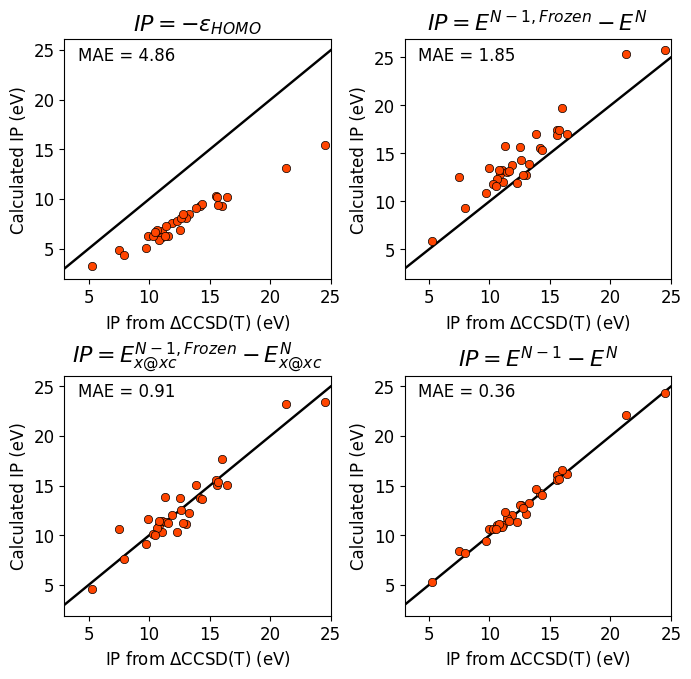

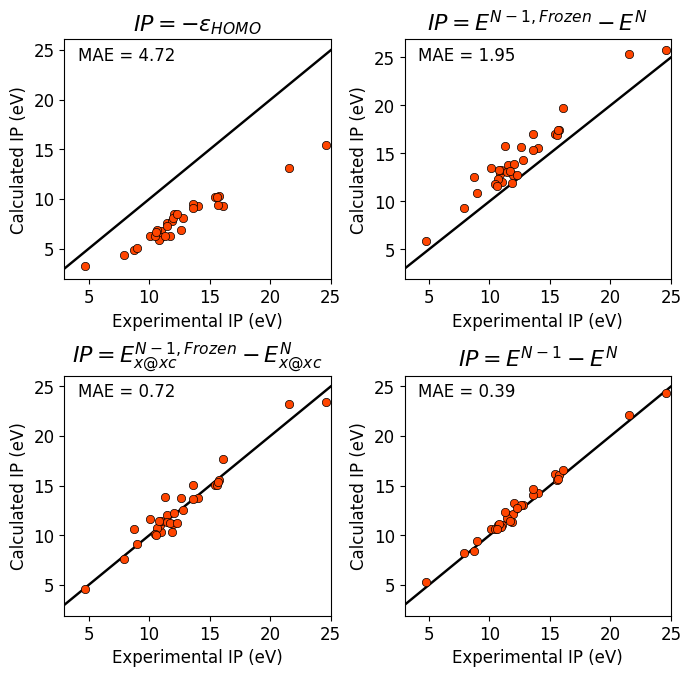

In [19]:
plot_all(e_homo_lda, ips_xc_frozen_lda, ips_xc_x_frozen_lda, ips_xc_lda, ips_ccsdt, "IP from $\\Delta$CCSD(T) (eV)")
plot_all(e_homo_lda, ips_xc_frozen_lda, ips_xc_x_frozen_lda, ips_xc_lda, ips_expt, "Experimental IP (eV)")

## PBE

Reading results from json/PBE_cc-pVTZ_20.json


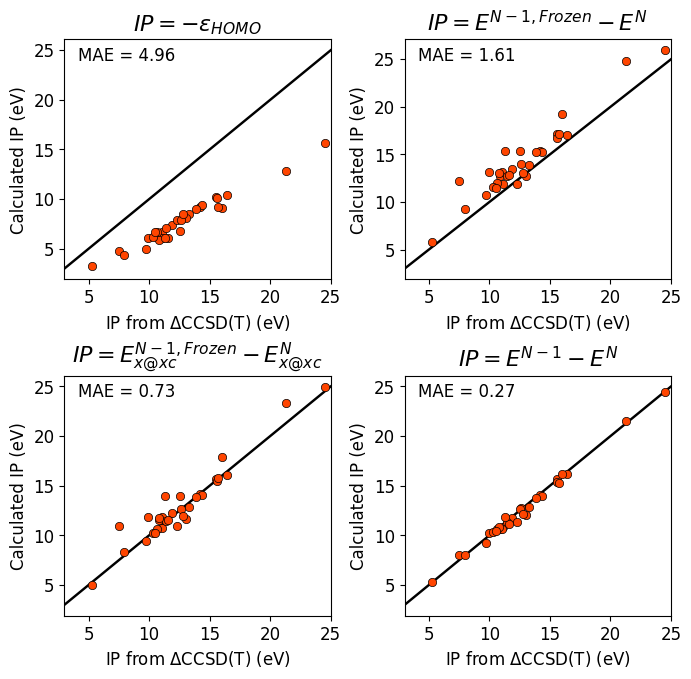

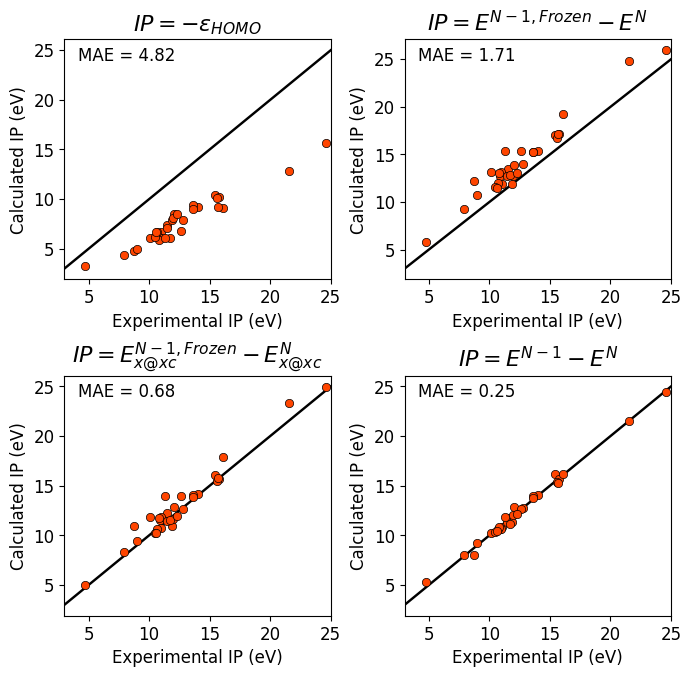

In [20]:
json_filename = f'json/PBE_{BASIS}_{MAX_NELEC}.json'

if os.path.isfile(json_filename):
    print(f'Reading results from {json_filename}')
    with open(json_filename, 'r') as file_obj:
        (systems2use, e_homo_pbe, ips_xc_frozen_pbe, ips_xc_x_frozen_pbe, ips_xc_pbe) = json.load(file_obj)
else:
    e_homo_pbe, ips_xc_frozen_pbe, ips_xc_x_frozen_pbe, ips_xc_pbe = eval_ips(systems2use, 'pbe', 'pbe,', AUXBASIS)
    with open(json_filename, 'w', encoding='utf-8') as file_obj:
        json.dump((systems2use, e_homo_pbe, ips_xc_frozen_pbe, ips_xc_x_frozen_pbe, ips_xc_pbe), file_obj, ensure_ascii=False, indent=4)

plot_all(e_homo_pbe, ips_xc_frozen_pbe, ips_xc_x_frozen_pbe, ips_xc_pbe, ips_ccsdt, "IP from $\\Delta$CCSD(T) (eV)")
plot_all(e_homo_pbe, ips_xc_frozen_pbe, ips_xc_x_frozen_pbe, ips_xc_pbe, ips_expt, "Experimental IP (eV)")

## r$^2$SCAN

Reading results from json/r2SCAN_cc-pVTZ_20.json


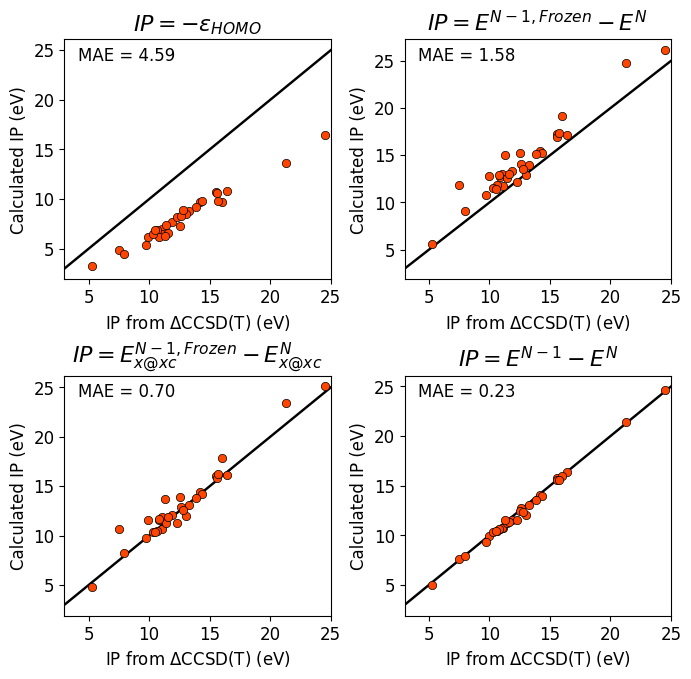

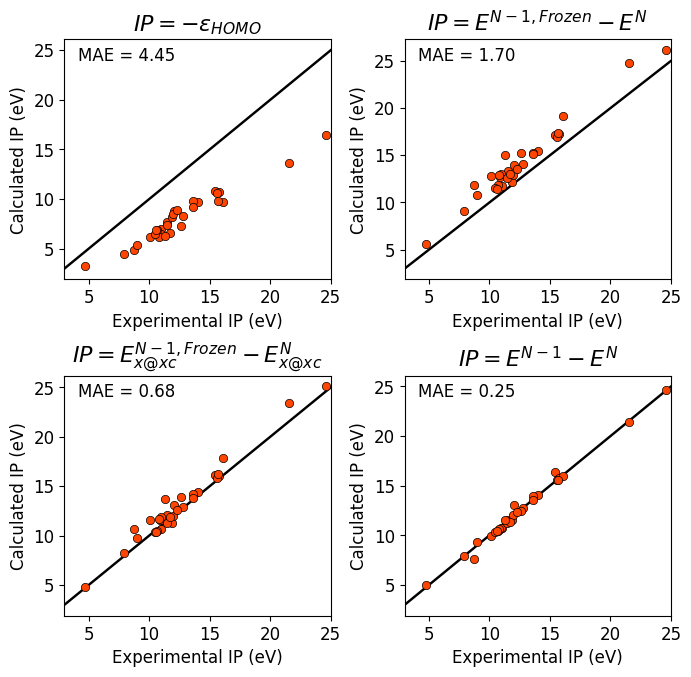

In [21]:
json_filename = f'json/r2SCAN_{BASIS}_{MAX_NELEC}.json'

if os.path.isfile(json_filename):
    print(f'Reading results from {json_filename}')
    with open(json_filename, 'r') as file_obj:
        (systems2use, e_homo_r2scan, ips_xc_frozen_r2scan, ips_xc_x_frozen_r2scan, ips_xc_r2scan) = json.load(file_obj)
else:
    e_homo_r2scan, ips_xc_frozen_r2scan, ips_xc_x_frozen_r2scan, ips_xc_r2scan = eval_ips(systems2use, 'r2SCAN', 'r2SCAN,', AUXBASIS)
    with open(json_filename, 'w', encoding='utf-8') as file_obj:
        json.dump((systems2use, e_homo_r2scan, ips_xc_frozen_r2scan, ips_xc_x_frozen_r2scan, ips_xc_r2scan), file_obj, ensure_ascii=False, indent=4)

plot_all(e_homo_r2scan, ips_xc_frozen_r2scan, ips_xc_x_frozen_r2scan, ips_xc_r2scan, ips_ccsdt, "IP from $\\Delta$CCSD(T) (eV)")
plot_all(e_homo_r2scan, ips_xc_frozen_r2scan, ips_xc_x_frozen_r2scan, ips_xc_r2scan, ips_expt, "Experimental IP (eV)")